# 08 · Recruitment case study

On 1 July 2016 AFC Bournemouth sold Matt Ritchie, the winger who had played the most minutes of
their first Premier League season, to Newcastle United for €12M. This notebook replays the decision
the club faced on 30 June 2016, the back-test's market view, with the tools the earlier notebooks
built and tested: who could replace Ritchie within the club's means, and who to sign. Only then
does it look at what happened.

1. **The vacancy.** What Ritchie did for Bournemouth, and how Bournemouth play.
2. **The long list.** The players who play most like Ritchie, within the budget, at clubs that
   would sell.
3. **The shortlist.** Among the nearest, the players the market valued furthest below their
   numbers, with their minutes and their fit to Bournemouth's style beside them.
4. **The recommendation and the scouting reports.** The shortlisted player who fits Bournemouth
   best, and a one-page report for each player on the shortlist, for Ritchie and for the player the
   club signed.
5. **What happened.** The recommendation, the shortlist and the players the club signed, three
   years on.

**The rules, set before any list was drawn up**, as the back-test's were (notebook 04):

- **The budget**: Ritchie's fee, €12M, turned into a ceiling on market value by what Premier League
  clubs paid over market value the summer before, the last one known on 30 June 2016 (section 2;
  the rule first read the summer of 2016, whose fees came after the decision, and keeps it as the
  check).
- **The candidates**: attacking midfielders and wingers aged 27 or under on 30 June 2016 who play
  on the right, outside Bournemouth and outside the strongest fifth of teams, which do not sell at
  their market value (notebook 04, section 1.6).
- **The long list**: the candidates ordered by their distance to Ritchie (the search of notebook
  06), the young players with fewer minutes in a list of their own.
- **The shortlist**: the five largest gaps within team (the ranking the back-test tested, notebook
  04) in the nearer half of the long list.
- **The recommendation**: the shortlisted player who fits Bournemouth's style best (notebook 07,
  section 4). Fit went with minutes at clubs that kept their coach, and Bournemouth kept Eddie Howe;
  as that split was found during the analysis, fit only decides among the five.
- Nothing after 30 June 2016 enters the choices; outcomes are read in section 5 only.

**Data:** [StatsBomb Open Data](https://github.com/statsbomb/open-data) (events, lineups), 2015/16,
the four complete leagues; Transfermarkt's market values, appearances, transfers and coaches. Only
aggregated results are shown, as StatsBomb's licence requires. Tables are built by `make model`;
see `docs/DATA_DICTIONARY.md`.

In [1]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import NullFormatter
from mplsoccer import Pitch
from scipy.ndimage import gaussian_filter

from football_scouting.analysis import recruitment
from football_scouting.analysis.backtest import chance
from football_scouting.analysis.market import gap, market_players, profile_matrix, team_strength
from football_scouting.analysis.metrics import LOWER_IS_BETTER
from football_scouting.analysis.outcomes import club_ids, coaches, league_share, player_outcomes
from football_scouting.analysis.profiles import LABELS, recording_context, rescale
from football_scouting.analysis.roles import place, style_matches
from football_scouting.analysis.similarity import (
    FOOT,
    in_common,
    main_positions,
    profile_gaps,
    search_players,
    search_points,
    search_values,
    similar,
    style_ends,
)
from football_scouting.analysis.style import LABELS as STYLE_LABELS
from football_scouting.analysis.style import touch_map
from football_scouting.analysis.teams import NUMBERS, numbers, style_axes, team_seasons
from football_scouting.analysis.values import pool_valuations, value_at
from football_scouting.config import PROJECT_ROOT, load_config
from football_scouting.model.database import connect_readonly
from football_scouting.plots import GREY, OKABE_ITO, credit, use_style
from football_scouting.reports import natural, role, strengths, write_reports

cfg = load_config()
con = connect_readonly(cfg)
use_style()

CASE = cfg.case_study  # the scenario
GROUP, CLUB, PLAYER = CASE.group, CASE.club, CASE.player
MARKET_VIEW = pd.Timestamp(cfg.backtest.market_view)  # 30 June 2016, the day of the decision
SEASON, SEASON_START = 2015, pd.Timestamp("2015-07-01")  # 2015/16 (Transfermarkt's season)
GROUP_NAMES = {g.code: g.name for g in cfg.comparison_groups}
AXIS_NAMES = dict(enumerate(cfg.roles.names[GROUP], start=1))  # the group's style axes
TEAM_AXIS_NAMES = dict(enumerate(cfg.team_style.names, start=1))
ZONE = 5  # yards, touch maps


def lower(label):
    """A label in lower case, abbreviations (xG) kept."""
    return label[0].lower() + label[1:]

## 1. The vacancy

What the club loses and how it plays, from the 2015/16 season and the values of 30 June 2016.

- **The club.** League place and points from the results; squad value: the sum of the market
  values on 30 June 2016 of the players whose latest valuation since 1 July 2015 named the club;
  the coach in the last league match of 2015/16 and the first of 2016/17 (Transfermarkt's games).
- **The player.** Ritchie's share of Bournemouth's league minutes (Transfermarkt's appearances),
  side and foot (notebook 06), profile (the twelve statistics of attacking midfielders and wingers
  as percentiles within the group, higher always better; notebook 02), the ends of the style axes
  Ritchie stands at (the bottom or top third of the group's regulars; notebook 05), and where
  Ritchie touched the ball (each match mirrored so that the player's side is at the bottom).
- **How the club plays.** Bournemouth among the 80 teams on the two team style axes (notebook
  07) and on the ten numbers behind them; the club's attacking midfielders and wingers together,
  the style a signing would fit or not (notebook 07, section 4), against the group's regulars; and
  each of them, with their side, foot and minutes.

### 1.1 The club and the player

In [2]:
players = con.sql("SELECT * FROM profile_players").df().set_index("player_id")
group = players.comparison_group
market = market_players(con, cfg).set_index("player_id")
style_recording = con.sql("SELECT * FROM style_recording").df()
rows = style_matches(con, cfg, group)  # each player's matches in their group's positions
rows = rescale(rows, group, recording_context(rows, cfg), style_recording)
who = search_players(con, cfg, market, rows)  # list, teams, foot, side, line, value
positions = main_positions(con, cfg, group)
team_names = con.sql("SELECT DISTINCT team_id, team_name FROM teams").df().set_index("team_id")
(club,) = team_names.index[team_names.team_name == CLUB]
(player,) = players.index[players.known_as == PLAYER]
POOL = [c.competition_id for c in cfg.statsbomb.competitions if c.scouting_pool]
team_map = con.sql("SELECT team_id, club_id, competition_id FROM team_map").df()
club_of = team_map[team_map.competition_id.isin(POOL)].set_index("team_id").club_id

table = recruitment.league_table(con)
league = table[table.competition_id == table.competition_id[club]]  # by place

valued = con.sql(f"""
    SELECT player_id, market_value_in_eur AS value, current_club_name AS name
    FROM tm_player_valuations
    WHERE date BETWEEN DATE '{SEASON_START:%Y-%m-%d}' AND DATE '{MARKET_VIEW:%Y-%m-%d}'
    QUALIFY row_number() OVER (PARTITION BY player_id ORDER BY date DESC) = 1
""").df()
squads = valued.groupby(valued.name.map(club_ids(con))).value.sum()
squad = squads.reindex(club_of.loc[league.index].to_numpy()).set_axis(league.index)
coach = coaches(con, SEASON + 1).loc[club_of[club]]
share = league_share(con, SEASON, pd.DataFrame({"player_id": [player],
                                                 "club_id": [club_of[club]]}))[0]  # fmt: skip
sale = recruitment.sale(con, player, SEASON + 1)  # the one transfer of the summer
assert squad.notna().all()

me, at = who.loc[player], league.loc[club]
squad_rank = squad.rank(ascending=False)[club]
facts = pd.Series({
    "League place, 2015/16": f"{at.place:.0f} of {len(league)}: {at.points:.0f} points, goal "
                             f"difference {at.goal_difference:+.0f}",
    "Squad value, 30 June 2016": f"€{squad[club] / 1e6:.0f}M, {squad_rank:.0f} of {len(squad)} "
                                 f"(the league's median €{squad.median() / 1e6:.0f}M)",
    "Coach": f"{coach.before} in the last league match of 2015/16, {coach.after} in the first of "
             "2016/17",
    "The player": f"{PLAYER}, {int(me.age)} on 30 June 2016, market value €{me.value / 1e6:.0f}M",
    "Position": f"{positions.position[player]}, the position played most among the group's",
    "Minutes": f"{players.minutes[player]:,.0f}, {share:.0%} of the club's league minutes; "
               f"{me.minutes:,.0f} in the group's positions",
    "Foot": f"{me.left_foot:.0%} of the passes played with either foot played with the left",
    "Sold": f"to {sale.to_club_name} on {sale.transfer_date.day} {sale.transfer_date:%B %Y}, "
            f"for €{sale.transfer_fee / 1e6:.0f}M",
})  # fmt: skip
display(facts.to_frame("").style.set_caption(f"{CLUB} and {PLAYER} on 30 June 2016"))

,
"League place, 2015/16","16 of 20: 42 points, goal difference -22"
"Squad value, 30 June 2016","€89M, 20 of 20 (the league's median €163M)"
Coach,"Eddie Howe in the last league match of 2015/16, Eddie Howe in the first of 2016/17"
The player,"Matt Ritchie, 26 on 30 June 2016, market value €6M"
Position,"Right Midfield, the position played most among the group's"
Minutes,"3,175, 87% of the club's league minutes; 3,124 in the group's positions"
Foot,66% of the passes played with either foot played with the left
Sold,"to Newcastle on 1 July 2016, for €12M"


### 1.2 What Ritchie did

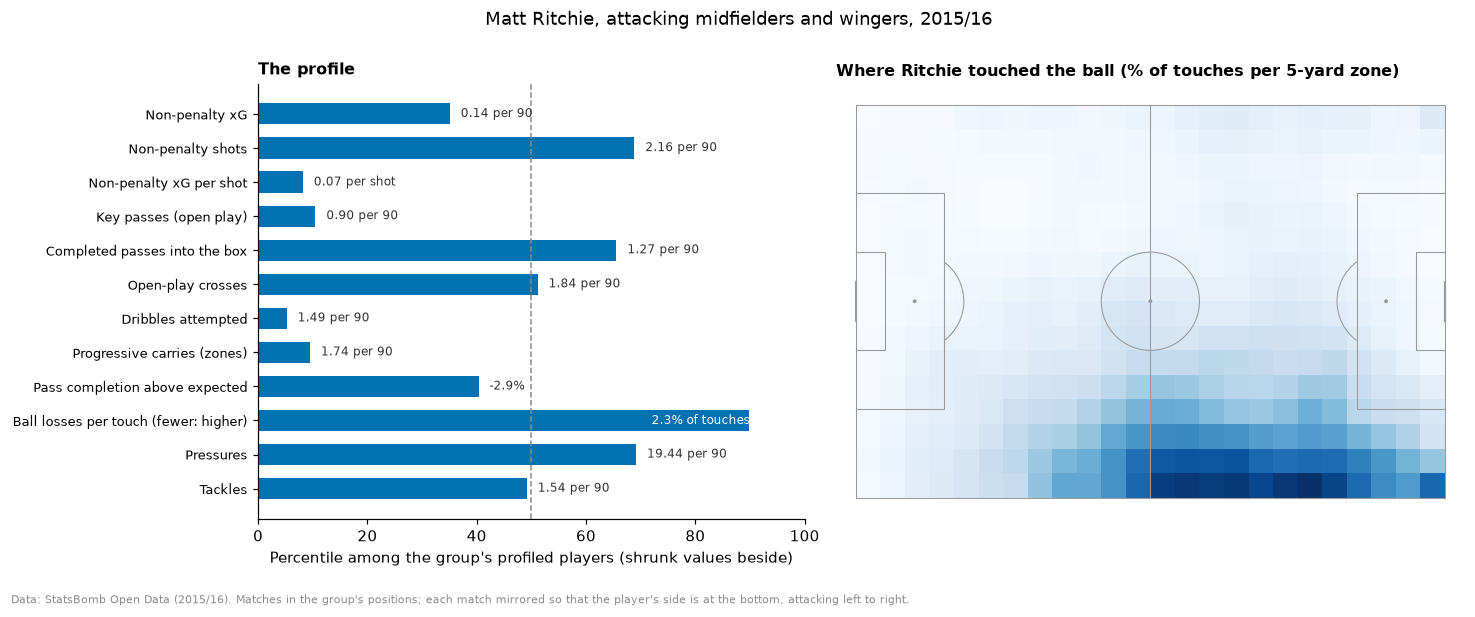

,Low end,High end,Score,Percentile among the regulars,Ritchie's end
Axis,,,,,
1,Link player,Final-third attacker,-1.10,15,Link player
2,Lay-off runner,Forward passer,+0.59,76,Forward passer
3,Inside forward,Touchline winger,+0.91,80,Touchline winger
4,Ball-carrier,Aerial presence,+0.14,62,between the two


Highest percentiles: ball losses per touch 90, pressures 69, non-penalty shots 69, completed passes into the box 66; lowest: dribbles attempted 5, non-penalty xG per shot 8, progressive carries (zones) 10, key passes (open play) 10.


In [3]:
values = con.sql("SELECT * FROM profile_values").df()
statistics = list(cfg.profiles[GROUP])
mine = values[values.player_id == player].set_index("statistic").loc[statistics]


pitch = Pitch(pitch_type="statsbomb", line_color="#9A9A9A", linewidth=0.7, line_zorder=2)
grid = pitch.bin_statistic(np.array([60.0]), np.array([40.0]), bins=(120 // ZONE, 80 // ZONE))
touches = touch_map(con, rows[rows.player_id == player], zone=ZONE)
fig, (left, right) = plt.subplots(1, 2, figsize=(13.5, 5.2),
                                  gridspec_kw={"width_ratios": [1, 1.15]})  # fmt: skip
y = np.arange(len(statistics))[::-1]
left.barh(y, mine.percentile, height=0.62, color=OKABE_ITO[0])
for yy, (s, row) in zip(y, mine.iterrows(), strict=True):
    left.text(min(row.percentile, 70) + 2, yy, natural(s, row.shrunk), va="center", fontsize=8,
              color="white" if row.percentile > 72 else "#333333")  # fmt: skip
left.axvline(50, color=GREY, lw=1, ls="--")
left.set_yticks(y, [LABELS[s] + (" (fewer: higher)" if s in LOWER_IS_BETTER else "")
                    for s in statistics], fontsize=8.5)  # fmt: skip
left.set_xlim(0, 100)
left.set_xlabel("Percentile among the group's profiled players (shrunk values beside)")
left.grid(axis="y", visible=False)
left.set_title("The profile", fontsize=10.5)
pitch.draw(ax=right)
grid["statistic"] = (
    gaussian_filter(
        touches.loc[player].to_numpy().reshape(80 // ZONE, 120 // ZONE), 0.8, mode="nearest"
    )
    * 100
)
pitch.heatmap(grid, ax=right, cmap="Blues", edgecolors="none")
right.set_title(f"Where Ritchie touched the ball (% of touches per {ZONE}-yard zone)",
                fontsize=10.5)  # fmt: skip
fig.suptitle(f"{PLAYER}, {GROUP_NAMES[GROUP].lower()}, 2015/16", y=1.0)
fig.tight_layout()
credit(fig, "Data: StatsBomb Open Data (2015/16). Matches in the group's positions; each match "
            "mirrored so that the player's side is at the bottom, attacking left to "
            "right.")  # fmt: skip
plt.show()

style_scores = con.sql("SELECT * FROM style_scores").df()
scores = style_scores[style_scores.comparison_group == GROUP].pivot(
    index="player_id", columns="axis", values="score"
)
regulars = who.index[(who.group == GROUP) & (who["list"] == "Regulars")]
ends = style_ends(scores, cfg.roles.names[GROUP], regulars)
axes_table = pd.DataFrame({
    "Low end": [AXIS_NAMES[a][0] for a in scores],
    "High end": [AXIS_NAMES[a][1] for a in scores],
    "Score": scores.loc[player],
    "Percentile among the regulars": 100 * scores.lt(scores.loc[player]).loc[regulars].mean(),
    "Ritchie's end": ends.loc[player].fillna("between the two"),
}, index=scores.columns).rename_axis(index="Axis")  # fmt: skip
display(
    axes_table.style.format({"Score": "{:+.2f}", "Percentile among the regulars": "{:.0f}"})
    .set_caption(f"Ritchie on the style axes of {GROUP_NAMES[GROUP].lower()} (scores in standard "
                 f"deviations of the {len(regulars)} regulars)")
)  # fmt: skip
top, bottom = mine.percentile.nlargest(4), mine.percentile.nsmallest(4)
print(
    "Highest percentiles: " + ", ".join(f"{lower(LABELS[s])} {p:.0f}" for s, p in top.items())
    + "; lowest: " + ", ".join(f"{lower(LABELS[s])} {p:.0f}" for s, p in bottom.items()) + "."
)  # fmt: skip

### 1.3 How Bournemouth play

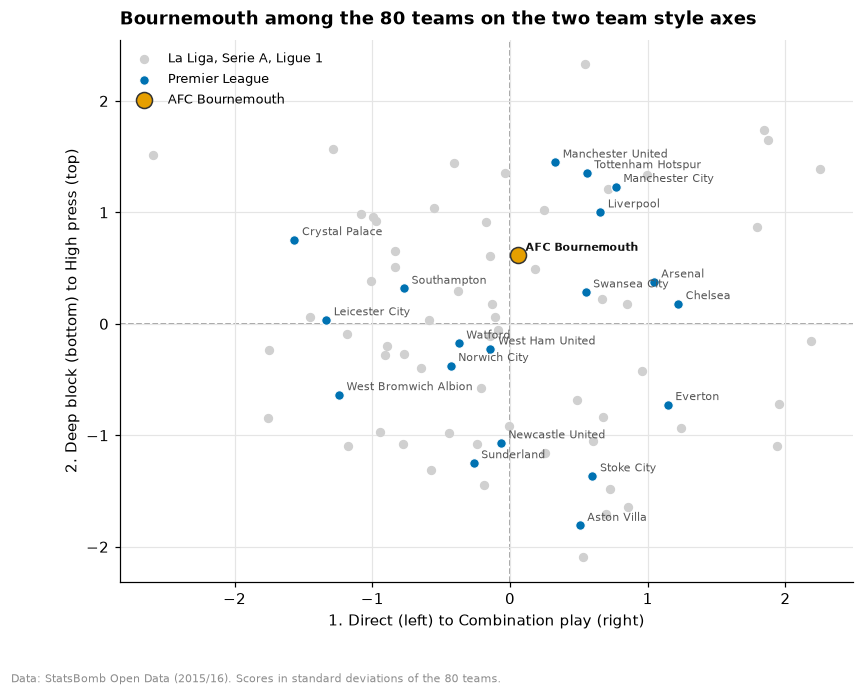

AFC Bournemouth on the team style axes: 1. direct to combination play +0.06, 11 of the league's 20 from the combination play end; 2. deep block to high press +0.61, 6 of the league's 20 from the high press end.


,AFC Bournemouth,Premier League mean,All 80 teams,Percentile of the 80
PPDA (opponent passes per defensive action),13.30,12.59,13.09,57
Height of defensive actions (x),43.80,42.83,42.59,70
Final-third pressures per pressure,0.22,0.20,0.20,86
Counterpressures per pressure,0.21,0.21,0.21,51
Yards gained per completed pass,3.22,3.65,3.92,14
Long passes per pass from the own third,0.30,0.32,0.30,44
Long goal kicks per goal kick,0.71,0.82,0.78,28
Wide entries into the final third,0.65,0.58,0.60,91
Crosses per final-third pass,0.11,0.11,0.12,25
Pass ease (expected completion),0.78,0.77,0.77,65


,Bournemouth's wide players,Ritchie
Spread of touches along the pitch,+1.24,+1.35
Height of defensive actions (x),-1.19,-0.84
Spread of touches across the pitch,-1.15,-0.78
"Touches in the box, per touch",-0.84,-1.19
"Inside foot share, wide",+0.76,+0.50
Clearances and blocks per action,+0.74,+0.99


,Position,Minutes in the group's positions,Left foot's share,Age,Value (€M)
Matt Ritchie,Right Midfield,"3,124",66%,26,6.0
Marc Pugh,Left Midfield,"1,442",18%,29,2.0
Junior Stanislas,Left Midfield,"1,402",9%,26,4.0
Max Gradel,Left Midfield,929,22%,28,8.0


In [4]:
seasons = team_seasons(con, cfg)  # every team's counts over the season, on one scale
team_axes = style_axes(seasons.season, cfg)
season_numbers = numbers(seasons.season)
team_scores = team_axes.scores(season_numbers)
league_of = seasons.recorded.groupby("team_id").competition_id.first()
in_league = league_of.index[league_of == league_of[club]]

fig, ax = plt.subplots(figsize=(8.6, 6.4))
others = team_scores.index.difference(in_league)
ax.scatter(team_scores.loc[others, 1], team_scores.loc[others, 2], s=26, color="#D0D0D0",
           label="La Liga, Serie A, Ligue 1", zorder=2)  # fmt: skip
peers = in_league.drop(club)
ax.scatter(team_scores.loc[peers, 1], team_scores.loc[peers, 2], s=40, color=OKABE_ITO[0],
           edgecolor="white", linewidth=0.8, label="Premier League", zorder=3)  # fmt: skip
ax.scatter(team_scores.at[club, 1], team_scores.at[club, 2], s=110, color=OKABE_ITO[1],
           edgecolor="#333333", linewidth=1, label=CLUB, zorder=4)  # fmt: skip
for team in in_league:
    ax.annotate(team_names.team_name[team], (team_scores.at[team, 1], team_scores.at[team, 2]),
                xytext=(5, 3), textcoords="offset points", fontsize=7,
                color="#111111" if team == club else "#555555",
                fontweight="bold" if team == club else "normal")  # fmt: skip
ax.axhline(0, color=GREY, lw=1, ls="--", zorder=1)
ax.axvline(0, color=GREY, lw=1, ls="--", zorder=1)
ax.set_xlabel(f"1. {TEAM_AXIS_NAMES[1][0]} (left) to {TEAM_AXIS_NAMES[1][1]} (right)")
ax.set_ylabel(f"2. {TEAM_AXIS_NAMES[2][0]} (bottom) to {TEAM_AXIS_NAMES[2][1]} (top)")
ax.set_title("Bournemouth among the 80 teams on the two team style axes", pad=10)
ax.legend(loc="upper left", fontsize=8.5)
ax.grid(color="#E5E5E5")
credit(fig, "Data: StatsBomb Open Data (2015/16). Scores in standard deviations of the 80 teams.")
plt.show()
from_top = team_scores.loc[in_league].rank(ascending=False).loc[club]
print(f"{CLUB} on the team style axes: " + "; ".join(
    f"{a}. {TEAM_AXIS_NAMES[a][0].lower()} to {TEAM_AXIS_NAMES[a][1].lower()} "
    f"{team_scores.at[club, a]:+.2f}, {from_top[a]:.0f} of the league's {len(in_league)} from "
    f"the {TEAM_AXIS_NAMES[a][1].lower()} end"
    for a in team_scores
) + ".")  # fmt: skip

kept = list(cfg.team_style.numbers)
rank = season_numbers[kept].rank(pct=True)
display(
    pd.DataFrame({
        CLUB: season_numbers.loc[club, kept],
        "Premier League mean": season_numbers.loc[in_league, kept].mean(),
        "All 80 teams": season_numbers[kept].mean(),
        "Percentile of the 80": 100 * rank.loc[club],
    }).rename(index=NUMBERS)
    .style.format("{:.2f}").format("{:.0f}", subset="Percentile of the 80")
    .set_caption("The ten numbers the team style axes are read from, over the season (counts on "
                 "one scale across recording contexts)")
)  # fmt: skip

style_descriptors = con.sql("SELECT * FROM style_descriptors").df()
style_values = con.sql("SELECT * FROM style_values").df()
in_group = rows[rows.player_id.map(group) == GROUP]
club_sums = in_group[in_group.team_id == club].groupby("team_id")[recruitment.STYLE_SUMS].sum()
club_style = place(club_sums, GROUP, style_descriptors).loc[club]  # all its players together
shrunk = style_values[style_values.comparison_group == GROUP].pivot(
    index="player_id", columns="descriptor", values="shrunk"
)[club_style.index]
mean, sd = shrunk.loc[regulars].mean(), shrunk.loc[regulars].std()
apart = pd.DataFrame(
    {
        "Bournemouth's wide players": (club_style - mean) / sd,
        "Ritchie": (shrunk.loc[player] - mean) / sd,
    }
).rename(index=STYLE_LABELS)
display(
    apart.loc[apart.iloc[:, 0].abs().sort_values(ascending=False).index[:6]]
    .style.format("{:+.2f}")
    .set_caption(f"The style descriptors on which the club's {GROUP_NAMES[GROUP].lower()} together "
                 f"stand furthest from the group's {len(regulars)} regulars (standard deviations "
                 "of the regulars; on an even share of possession)")
)  # fmt: skip

wide = who[(who.group == GROUP) & who.teams.map(lambda t: club in t)]
display(
    pd.DataFrame({
        "Position": positions.position.loc[wide.index],
        "Minutes in the group's positions": wide.minutes,
        "Left foot's share": wide.left_foot,
        "Age": wide.age.astype(int),
        "Value (€M)": wide.value / 1e6,
    }).set_index(wide.name).sort_values("Minutes in the group's positions", ascending=False)
    .rename_axis(index=None)
    .style.format({"Minutes in the group's positions": "{:,.0f}", "Left foot's share": "{:.0%}",
                   "Value (€M)": "{:.1f}"})
    .set_caption(f"{CLUB}'s profiled {GROUP_NAMES[GROUP].lower()} in 2015/16")
)  # fmt: skip

### What section 1 shows

- **The club.** Bournemouth finished 16th of 20 in their first Premier League season, with 42 points
  and a goal difference of −22, and had the league's smallest squad by market value: €89M on 30 June
  2016, against a median of €163M. Eddie Howe coached the last match of 2015/16 and the first of
  2016/17.
- **The player.** Ritchie, 26, played 87% of the club's league minutes, almost all of them at right
  midfield, and plays two passes in three with the left foot: a left-footer on the right. Valued at
  €6M on 30 June 2016, sold for €12M the next day.
- **What Ritchie did.** A wide midfielder who works both ways rather than a dribbler. High in the
  group for ball security (90th percentile), pressures (69th), shots (69th) and passes into the box
  (66th); low for dribbles (5th), progressive carries (10th), key passes (10th) and xG per shot (8th):
  many shots from far out. On the style axes, a link player rather than a final-third attacker, a
  forward passer and a touchline winger. The touches run the length of the right touchline, from the
  own half to the edge of the box, and rarely into it.
- **How Bournemouth play.** In the middle of the direct-to-combination axis (+0.06, 11th of the
  league's 20 from the combination end) and towards the high press (+0.61, 6th). Among the 80 teams they gain few yards per completed pass (14th percentile), enter the
  final third wide more than most (91st) and press high (86th for the share of pressures in the
  final third). Their attacking midfielders and wingers together cover the length of the flank,
  stay wide, defend deep and come into the box rarely, the style a signing would fit or not;
  Ritchie stands at the same end of each of those descriptors.
- **The vacancy.** The club's three other profiled wide players played on the left. The role to fill
  is a right-sided wide midfielder who covers the flank both ways; Ritchie's foot is shown for the
  candidates but not required, as set beforehand.

## 2. The long list

The players who play most like Ritchie among those the club could afford and buy.

- **The budget.** Every transfer on record from 1 May to 31 August with a fee: the fee against the
  player's market value on 30 June of that year, by the league the buying club played in in the
  season starting then. Transfermarkt dates summer transfers from 1 July, so the fees of the summer
  of 2016 were not known on 30 June 2016: Ritchie's fee over the median ratio Premier League clubs
  paid for profiled players in the summer of 2015 is the ceiling on a candidate's market value,
  and the summer of 2016 is the check. Transfers are on record for few players, so the ratio is a
  rough guide; the same ratio for every player valued on 30 June, profiled or not, is a second
  check.
- **The candidates.** The attacking midfielders and wingers in the search's two lists (notebook
  06: the regulars, with 900 minutes or more in the group's positions, and the young players,
  under 23 with 450 to 899), then the filters in turn: not one of Ritchie's teammates; playing on
  the right (the side of the position they spent most time in among the group's); 27 or under on
  30 June 2016; valued at or under the ceiling; their main team outside the strongest fifth of the
  80 by goal difference per match.
- **The order.** The distance from Ritchie in the search's space (the shrunk style descriptors and
  the profile; notebook 06), list by list, with the ends of the style axes a candidate shares with
  Ritchie and the profile statistics they are furthest above and below Ritchie on. The nearer half
  of each list (rounded up) is where the shortlist is drawn from (section 3).

### 2.1 The budget

In [5]:
league_name = {c.transfermarkt_competition_id: c.name for c in cfg.statsbomb.competitions
               if c.scouting_pool}  # fmt: skip
(home,) = [c.transfermarkt_competition_id for c in cfg.statsbomb.competitions
           if c.competition_id == league_of[club]]  # fmt: skip
SUMMERS = [SEASON, SEASON + 1]  # the summer before, known on 30 June 2016, and its own
paid = pd.concat([recruitment.fee_ratios(con, cfg, players.index, year).assign(summer=year)
                  for year in SUMMERS], ignore_index=True)  # fmt: skip


def median_ratio(ratios):
    return f"{ratios.median():.2f} ({len(ratios)})"


display(
    pd.DataFrame({
        (f"Summer of {year}", sold): d[d.summer == year].groupby("league").ratio.agg(median_ratio)
        for year in SUMMERS
        for sold, d in (("Profiled players", paid[paid.profiled]), ("Every player", paid))
    }).T.rename(columns=league_name)[list(league_name.values())]
    .style.set_caption("Fees paid from 1 May to 31 August against the market value on 30 June, by "
                       "the buying club's league in the season starting then: median ratio "
                       "(transfers with a fee on record)")
)  # fmt: skip
home_paid = paid[paid.profiled & (paid.league == home)].groupby("summer").ratio
ratio, quartiles = home_paid.median(), home_paid.quantile([0.25, 0.75]).unstack()
CEILING = recruitment.ceiling(sale.transfer_fee, paid[paid.summer == SEASON], home)
spread = {y: f"quartiles {quartiles.at[y, 0.25]:.2f} and {quartiles.at[y, 0.75]:.2f}"
          for y in SUMMERS}  # fmt: skip
print(
    f"The earliest summer transfer on record is dated {paid.transfer_date.min():%-d %B %Y}; in "
    f"2016, {paid.transfer_date[paid.summer == SEASON + 1].min():%-d %B}. Premier League clubs "
    f"paid a median {ratio[SEASON]:.2f} times the market value for the profiled players they "
    f"bought in the summer of {SEASON} ({spread[SEASON]}): Ritchie's fee, "
    f"€{sale.transfer_fee / 1e6:.0f}M, buys a player valued at up to €{CEILING / 1e6:.2f}M on 30 "
    f"June 2016. At the summer of {SEASON + 1}'s ratio, {ratio[SEASON + 1]:.2f} "
    f"({spread[SEASON + 1]}), it would buy one valued at up to "
    f"€{sale.transfer_fee / ratio[SEASON + 1] / 1e6:.2f}M. Ritchie was valued at "
    f"€{who.value[player] / 1e6:.1f}M."
)  # fmt: skip

The earliest summer transfer on record is dated 1 July 2015; in 2016, 1 July. Premier League clubs paid a median 1.53 times the market value for the profiled players they bought in the summer of 2015 (quartiles 1.25 and 2.00): Ritchie's fee, €12M, buys a player valued at up to €7.85M on 30 June 2016. At the summer of 2016's ratio, 1.99 (quartiles 1.55 and 2.25), it would buy one valued at up to €6.04M. Ritchie was valued at €6.0M.


### 2.2 The candidates

In [6]:
strength = team_strength(con).set_index("team_id").goal_difference
who["team_fifth"] = market.team_id.map(recruitment.team_fifths(strength))  # 5: the strongest
search = search_points(search_values(style_values, values, GROUP), regulars)
found = similar(search, who, player, n=None)  # every candidate, Ritchie's teammates left out
steps = {"In the search's lists": who[(who.group == GROUP) & who["list"].notna()].drop(player)}
steps |= recruitment.candidates(found, side=who.side[player], younger_than=CASE.younger_than,
                                max_value=CEILING, fifth=who.team_fifth)  # fmt: skip
display(
    pd.DataFrame({step: d["list"].value_counts() for step, d in steps.items()}).T
    .reindex(columns=["Regulars", "Young"]).fillna(0).astype(int)
    .assign(All=lambda d: d.sum(axis=1))
    .style.set_caption(f"The candidates, filter by filter ({GROUP_NAMES[GROUP].lower()})")
)  # fmt: skip
long_list = recruitment.long_list(steps["Outside the strongest fifth"])  # place, nearer half
REASONS = {"On the right": "playing on the left or in the centre", "27 or under": "28 or over",
           "Within the budget": "over the budget",
           "Outside the strongest fifth": "at a team of the strongest fifth"}  # fmt: skip
nearer = found[found.distance < found["list"].map(long_list.groupby("list").distance.min())]
left_out = pd.Series([next(REASONS[s] for s in REASONS if i not in steps[s].index)
                      for i in nearer.index], index=nearer.index)  # fmt: skip
for name, reasons in left_out.groupby(nearer["list"]):
    print(f"{name}: {len(reasons)} candidates nearer Ritchie than the first of the long list, "
          "left out as " + ", ".join(f"{r} ({n})" for r, n in reasons.value_counts().items())
          + ".")  # fmt: skip

list,Regulars,Young,All
In the search's lists,252,27,279
Not a teammate,249,27,276
On the right,101,13,114
27 or under,67,13,80
Within the budget,37,8,45
Outside the strongest fifth,34,8,42


Regulars: 14 candidates nearer Ritchie than the first of the long list, left out as playing on the left or in the centre (11), 28 or over (2), over the budget (1).
Young: 2 candidates nearer Ritchie than the first of the long list, left out as playing on the left or in the centre (2).


### 2.3 The long list

In [7]:
percentiles = values[values.comparison_group == GROUP].pivot(
    index="player_id", columns="statistic", values="percentile"
)
gaps = profile_gaps(percentiles, player, long_list.index)


def furthest(way):
    return (gaps[way].map(LABELS) + gaps[f"{way}_by"].map(" ({:+.0f})".format)).fillna("–")


display(
    pd.DataFrame({
        "Player": long_list.name, "Team": long_list.team, "League": long_list.league,
        "Age": long_list.age.astype(int), "Minutes": long_list.minutes,
        "Value (€M)": long_list.value / 1e6,
        "Foot": np.where(long_list.left_foot >= FOOT, "Left", "Right"),
        "Distance": long_list.distance, "Place among all": found.place[long_list.index],
        "Style in common": in_common(ends, player, long_list.index),
        "Better on": furthest("above"), "Worse on": furthest("below"),
        "Nearer half": np.where(long_list.nearer_half, "✓", ""),
    }).set_index([long_list["list"].rename("List"), long_list.place.rename("Place")])
    .style.format({"Minutes": "{:,.0f}", "Value (€M)": "{:.1f}", "Distance": "{:.2f}"})
    .set_caption(f"The long list: the candidates nearest {PLAYER}, list by list (place among all: "
                 "among every candidate of the list who was not a teammate; better and worse on: "
                 "the profile statistic furthest above and below Ritchie, in percentile points)")
)  # fmt: skip
for name, d in long_list.groupby("list"):
    every = found[found["list"] == name]
    print(f"{name}: {len(d)} on the long list, the nearer {d.nearer_half.sum()} kept for the "
          f"shortlist. The nearest candidate of the list before the filters, "
          f"{every.name.iloc[0]} ({every.team.iloc[0]}), is {every.distance.iloc[0]:.2f} from "
          f"Ritchie; the nearest on the long list, {d.name.iloc[0]}, {d.distance.iloc[0]:.2f}; "
          f"the median candidate of the list, {every.distance.median():.2f}.")  # fmt: skip
check = sale.transfer_fee / ratio[SEASON + 1]
dearer = long_list[long_list.value > check]
print(f"Valued above €{check / 1e6:.2f}M, the ceiling at the summer of {SEASON + 1}'s ratio: "
      + "; ".join(f"{r['name']} (€{r.value / 1e6:.1f}M, {r['list'].lower()} {r.place})"
                  for _, r in dearer.iterrows()) + ".")  # fmt: skip

Regulars: 34 on the long list, the nearer 17 kept for the shortlist. The nearest candidate of the list before the filters, Thibault Giresse (Guingamp), is 1.04 from Ritchie; the nearest on the long list, Adrien Thomasson, 1.31; the median candidate of the list, 1.79.
Young: 8 on the long list, the nearer 4 kept for the shortlist. The nearest candidate of the list before the filters, Ricardo Horta (Málaga), is 1.15 from Ritchie; the nearest on the long list, Ludovic Blas, 1.24; the median candidate of the list, 1.65.
Valued above €6.04M, the ceiling at the summer of 2016's ratio: Nathan Redmond (€7.5M, regulars 6); Santi Mina (€7.0M, regulars 17); Jordon Ibe (€7.0M, regulars 29).


### What section 2 shows

- **The budget.** Transfermarkt dates summer transfers from 1 July, after the decision, so the
  ceiling comes from the summer before. In the summer of 2015 Premier League clubs paid a median 1.53
  times the market value for the 37 profiled players they bought (1.25 to 1.33 in the other three
  leagues): Ritchie's €12M buys a player valued at up to €7.85M. The check: in the summer of 2016 the
  Premier League's ratio rose to 1.99 (23 transfers) while the other leagues' fell to 1.05 to 1.19,
  and at that ratio the fee buys a player valued at €6.04M, Ritchie's own value. The ceiling is
  generous by the market the club met; three players on the long list are valued above the lower
  one (Redmond, Santi Mina and Ibe).
- **The candidates.** Of the 276 attacking midfielders and wingers in the search's lists who never
  played with Ritchie, 114 play on the right, 80 of those are 27 or under, 45 of those are within
  the budget and 42 play outside the strongest fifth of teams: 34 regulars and 8 young players. The
  side costs the most: of the 14 regulars nearer Ritchie than the first on the long list, 11 play
  on the left or in the centre (and both young players nearer than the first of their list).
- **The long list.** The nearest regular, Adrien Thomasson (Nantes, 22, €2.5M), is 1.31 from
  Ritchie, the 15th nearest of the 249 regulars; the nearest of all is 1.04 away and the median
  candidate 1.79. The nearer half of the regulars, kept for the shortlist, runs to Santi Mina
  (Valencia), the 119th nearest of all; the nearer half of the young players to Suso (Genoa). For
  28 of the 42 the statistic they fall furthest below Ritchie on is ball losses per touch, where
  Ritchie is at the 90th percentile, and for 9 it is non-penalty shots; 40 are furthest above
  Ritchie on dribbles, progressive carries, key passes or xG per shot, where Ritchie is low. 12 of
  the 42 are left-footed, as Ritchie is.
- **A caveat on who would sell.** The strongest fifth is a coarse rule: Jesse Lingard, a Manchester
  United academy player valued at €5M, passes it (Manchester United are in the fourth fifth) and is
  8th of the regulars.

## 3. The shortlist

Among the nearer half of each list, the five players the market valued furthest below their
numbers, with their minutes and their fit to Bournemouth's style beside them.

- **The gap within team** (notebook 04): the log of the model's value less the log of the market's.
  The model, a ridge regression, reads age, minutes, the league, the team's goal difference per
  match and the twelve profile statistics; it is fitted on every profiled attacking midfielder and
  winger, and each player is predicted by models that never saw their team. With the team's
  strength in the model, a player is compared with players at teams as strong, so the players of
  weak teams are not found cheap for their team alone (notebook 04, section 1.6). It is the
  ranking the back-test read first: its picks were at the 63rd percentile of their age band three
  years on (notebook 04, section 3).
- **The fit to Bournemouth** (notebook 07, section 4): the share of the other clubs whose style the
  player is further from, 1 the best fit and 0.5 an average club. The style is read from the style
  descriptors on an even share of possession, the team's part taken out on both sides (the
  player's at their last team's style without them, Bournemouth's at its own); Bournemouth's style
  is that of all its attacking midfielders and wingers in 2015/16, Ritchie included, as the fit of
  notebook 07 read every club. Fit decides among the five (section 4); here it is shown only.

,Team,Age,League minutes,Value (€M),Model (€M),Model over value,Gap: percentile in the group,List,Place,Distance,Fit to Bournemouth,Shortlist
Player,,,,,,,,,,,,
Ludovic Blas,Guingamp,18,680,0.3,1.1,3.78,98,Young,1,1.24,0.64,✓
Adri Embarba,Rayo Vallecano,24,"1,918",1.0,2.7,2.69,94,Regulars,11,1.63,0.79,✓
Lorenzo Pasciuti,Carpi,26,"1,636",1.3,3.0,2.30,91,Regulars,4,1.47,0.92,✓
Jesse Lingard,Manchester United,23,"1,734",5.0,9.8,1.96,86,Regulars,8,1.60,0.32,✓
Suso,Genoa,22,"1,260",3.3,5.3,1.61,77,Young,4,1.41,0.24,✓
Adrien Thomasson,Nantes,22,"2,621",2.5,3.9,1.55,74,Regulars,1,1.31,0.50,
Gilles Sunu,Angers,25,"2,489",2.0,3.0,1.49,73,Regulars,9,1.62,0.08,
Aleksandar Tonev,Frosinone,26,"1,146",0.9,1.3,1.47,72,Regulars,13,1.70,0.14,
Luca Paganini,Frosinone,23,"1,942",1.2,1.6,1.32,68,Regulars,7,1.58,0.66,


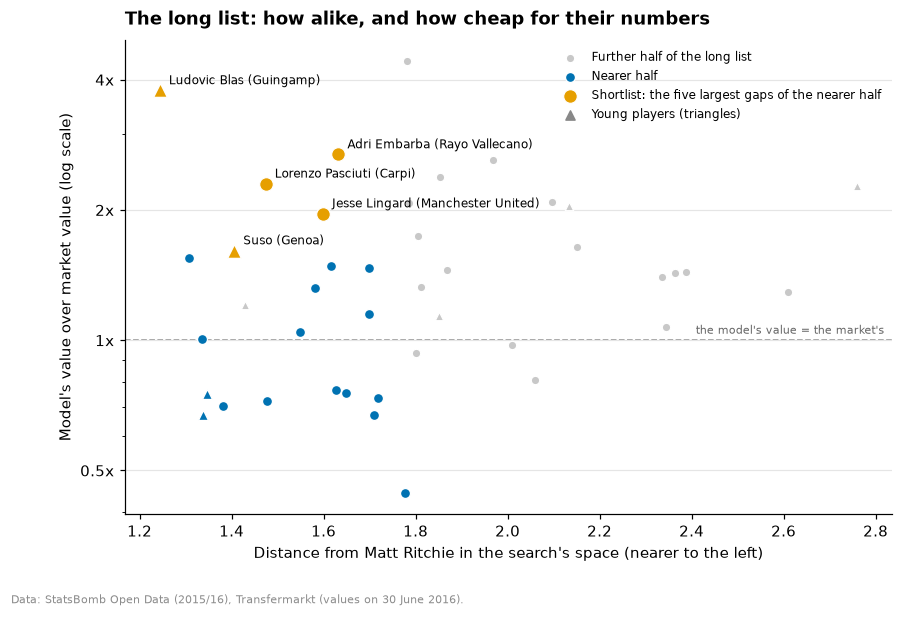

Shortlist: Ludovic Blas (Guingamp, 18, €0.3M, the model €1.1M; young 1, fit 0.64; Forward passer); Adri Embarba (Rayo Vallecano, 24, €1.0M, the model €2.7M; regulars 11, fit 0.79; Forward passer, Touchline winger); Lorenzo Pasciuti (Carpi, 26, €1.3M, the model €3.0M; regulars 4, fit 0.92; Link player, Forward passer, Touchline winger); Jesse Lingard (Manchester United, 23, €5.0M, the model €9.8M; regulars 8, fit 0.32; Link player); Suso (Genoa, 22, €3.3M, the model €5.3M; young 4, fit 0.24; no style axis end in common).
The long list's fit to Bournemouth: a median 0.34, from 0.03 to 0.96; the nearer half 0.54. The model's value over the market's: a median 1.05 in the nearer half, 1.44 in the further half. Next after the shortlist: Adrien Thomasson (1.55).


In [8]:
LEAGUES = [c.name for c in cfg.statsbomb.competitions if c.scouting_pool]
profile = profile_matrix(values, GROUP, cfg.profiles[GROUP])
group_gap = gap(market, profile, LEAGUES)  # within team: the model reads the team's strength
long_list["gap"] = group_gap.loc[long_list.index]
long_list["gap_percentile"] = 100 * group_gap.rank(pct=True).loc[long_list.index]

last_team = recruitment.last_teams(con)
long_list["fit"] = recruitment.club_fit(
    in_group, seasons, team_axes, style_values, style_descriptors, GROUP, regulars,
    long_list.index, club, last_team,
)  # fmt: skip

nearer = long_list[long_list.nearer_half].sort_values("gap", ascending=False)
SHORT = CASE.shortlist
shortlist = recruitment.shortlist(long_list, SHORT)
display(
    pd.DataFrame({
        "Player": nearer.name, "Team": nearer.team, "Age": nearer.age.astype(int),
        "League minutes": players.minutes.loc[nearer.index], "Value (€M)": nearer.value / 1e6,
        "Model (€M)": nearer.value * np.exp(nearer.gap) / 1e6,
        "Model over value": np.exp(nearer.gap),
        "Gap: percentile in the group": nearer.gap_percentile,
        "List": nearer["list"], "Place": nearer.place, "Distance": nearer.distance,
        "Fit to Bournemouth": nearer.fit,
        "Shortlist": np.where(nearer.index.isin(shortlist.index), "✓", ""),
    }).set_index("Player")
    .style.format({"League minutes": "{:,.0f}", "Value (€M)": "{:.1f}", "Model (€M)": "{:.1f}",
                   "Model over value": "{:.2f}", "Gap: percentile in the group": "{:.0f}",
                   "Distance": "{:.2f}", "Fit to Bournemouth": "{:.2f}"})
    .set_caption(f"The nearer half of the long list by the gap within team ({len(nearer)} "
                 f"players; the gap's percentile among the group's {len(group_gap)} profiled "
                 "players)")
)  # fmt: skip

fig, ax = plt.subplots(figsize=(9, 5.6))
far = long_list[~long_list.nearer_half]
for d, color, size, label in (
    (far, "#C8C8C8", 30, "Further half of the long list"),
    (nearer.drop(shortlist.index), OKABE_ITO[0], 42, "Nearer half"),
    (shortlist, OKABE_ITO[1], 80, "Shortlist: the five largest gaps of the nearer half"),
):
    for name, marker in (("Regulars", "o"), ("Young", "^")):
        part = d[d["list"] == name]
        ax.scatter(part.distance, np.exp(part.gap), s=size, color=color, marker=marker,
                   edgecolor="white", linewidth=0.8, zorder=3,
                   label=label if name == "Regulars" else None)  # fmt: skip
for _, r in shortlist.iterrows():
    ax.annotate(f"{r['name']} ({r.team})", (r.distance, np.exp(r.gap)), xytext=(6, 4),
                textcoords="offset points", fontsize=8)  # fmt: skip
ax.axhline(1, color=GREY, lw=1, ls="--", zorder=1)
ax.text(0.99, 1.02, "the model's value = the market's", transform=ax.get_yaxis_transform(),
        ha="right", va="bottom", fontsize=7.5, color="#666666")  # fmt: skip
ax.set_yscale("log")
ax.set_yticks([0.5, 1, 2, 4], ["0.5x", "1x", "2x", "4x"])
ax.yaxis.set_minor_formatter(NullFormatter())
ax.set_xlabel(f"Distance from {PLAYER} in the search's space (nearer to the left)")
ax.set_ylabel("Model's value over market value (log scale)")
ax.set_title("The long list: how alike, and how cheap for their numbers", pad=10)
ax.scatter([], [], marker="^", color="#888888", label="Young players (triangles)")
ax.legend(fontsize=8, loc="upper right")
credit(fig, "Data: StatsBomb Open Data (2015/16), Transfermarkt (values on 30 June 2016).")
plt.show()
print(
    "Shortlist: " + "; ".join(
        f"{r['name']} ({r.team}, {int(r.age)}, €{r.value / 1e6:.1f}M, the model "
        f"€{r.value * np.exp(r.gap) / 1e6:.1f}M; {r['list'].lower()} {r.place}, fit {r.fit:.2f}; "
        + (in_common(ends, player, [i]).iloc[0] or "no style axis end in common") + ")"
        for i, r in shortlist.iterrows()
    ) + "."
)  # fmt: skip
print(f"The long list's fit to Bournemouth: a median {long_list.fit.median():.2f}, from "
      f"{long_list.fit.min():.2f} to {long_list.fit.max():.2f}; the nearer half "
      f"{nearer.fit.median():.2f}. The model's value over the market's: a median "
      f"{np.exp(nearer.gap.median()):.2f} in the nearer half, {np.exp(far.gap.median()):.2f} in "
      f"the further half. Next after the shortlist: {nearer.name.iloc[SHORT]} "
      f"({np.exp(nearer.gap.iloc[SHORT]):.2f}).")  # fmt: skip

### What section 3 shows

- **The shortlist.** The five largest gaps of the nearer half: Ludovic Blas (Guingamp, 18, €0.3M
  against the model's €1.1M), Adri Embarba (Rayo Vallecano, 24, €1.0M against €2.7M), Lorenzo
  Pasciuti (Carpi, 26, €1.3M against €3.0M), Jesse Lingard (Manchester United, 23, €5.0M against
  €9.8M) and Suso (Genoa, 22, €3.3M against €5.3M): 1.6 to 3.8 times their market value, between
  the 77th and the 98th percentile of the group's gaps. Two are young players with few minutes
  (Blas 680 in the league, Suso 1,260); Embarba and Pasciuti played for clubs that finished 18th
  and went down. Adrien Thomasson, the nearest regular, misses it by a little (1.55 times the
  value, against Suso's 1.61).
- **Cheap and alike pull apart.** The nearer half of the long list is valued close to its numbers
  (the model's value a median 1.05 times the market's), the further half below them (1.44): the
  players least like Ritchie, many of them dribblers who keep the ball less, are the cheaper for
  their numbers. The shortlist is the nearer half's exceptions.
- **Fit.** The nearer half fits Bournemouth's style, which Ritchie's minutes shape, better than
  the rest: the long list's fit has a median of 0.34, its nearer half 0.54. On the shortlist it
  runs from 0.24 (Suso) and 0.32 (Lingard) to 0.92 (Pasciuti), whose style is further from 92% of
  the other clubs' styles than from Bournemouth's.
- **Who would sell.** Lingard is on the shortlist: the rule on the strongest fifth lets a
  Manchester United academy player through (section 2), and the gap reads a €5M value at a club
  that would not sell at it. As fit decides among the five (section 4), the doubt does not change
  the recommendation; it is noted in the report.

## 4. The recommendation and the scouting reports

- **The recommendation**, by the rule set beforehand: the shortlisted player who fits Bournemouth's
  style best. The five side by side, with what fit leaves aside: the gap, the distance from
  Ritchie, the minutes, the team's season, and each player's strengths and weaknesses.
- **Against Ritchie**: the recommended player's profile, touches and style beside Ritchie's.
- **The scouting reports**: one HTML page for each player on the shortlist, for Ritchie and for
  Jordon Ibe, the player of the group the club signed for 2016/17 (at the club from July to
  December 2016 by Transfermarkt's appearances, read only to choose whose page to write). Every
  page reads only what was known on 30 June 2016:
  - who the player is: team, age, main position, foot, minutes;
  - the profile, as a pizza of the twelve percentiles with Ritchie's as outlines, and in each
    statistic's own unit;
  - strengths and weaknesses: the statistics at the 80th percentile or above and at the 20th or
    below, at most three of each, the furthest from the middle first;
  - where the player touched the ball and shot from;
  - the style axes beside Ritchie's, the axis ends in common, and the statistics furthest above
    and below Ritchie;
  - the market value against the model's, the fit to Bournemouth, the distance from Ritchie and
    the five nearest regulars in the search's space, teammates included;
  - notes on what the numbers leave out: a young player's fewer minutes, a team in the fourth
    fifth (next to the strongest, which the rules leave out), a team in the relegation places.

  `make reports` writes them to `reports/scouting/`, with an index page:
  `analysis.recruitment.case_study` takes sections 2 and 3 again from the config and `reports`
  draws the pages. This section writes the same files and checks that the package's steps give
  this notebook's lists.

### 4.1 The shortlist side by side

In [9]:
recommended = recruitment.recommend(shortlist)
side = shortlist.sort_values("fit", ascending=False)
size = table.groupby("competition_id").place.transform("max")
team_of = market.team_id.loc[side.index]
display(
    pd.DataFrame({
        "Player": side.name, "Team": side.team,
        "Team's place": [f"{table.place[t]} of {size[t]}" for t in team_of],
        "Age": side.age.astype(int), "League minutes": players.minutes.loc[side.index],
        "Value (€M)": side.value / 1e6, "Model over value": np.exp(side.gap),
        "Distance": side.distance, "List": side["list"], "Place": side.place,
        "Style in common": in_common(ends, player, side.index), "Fit to Bournemouth": side.fit,
    }).set_index("Player")
    .style.format({"League minutes": "{:,.0f}", "Value (€M)": "{:.1f}",
                   "Model over value": "{:.2f}", "Distance": "{:.2f}",
                   "Fit to Bournemouth": "{:.2f}"})
    .set_caption("The shortlist by fit to Bournemouth's style, the rule's last step (team's place: "
                 "in its league in 2015/16)")
)  # fmt: skip


def listed(points):
    return ", ".join(f"{lower(LABELS[s])} {p:.0f}" for s, p in points.items()) or "none"


extremes = {i: strengths(percentiles.loc[i, statistics]) for i in side.index}
display(
    pd.DataFrame({
        "Strengths (80th percentile or above)": {i: listed(e[0]) for i, e in extremes.items()},
        "Weaknesses (20th or below)": {i: listed(e[1]) for i, e in extremes.items()},
    }).set_index(side.name).rename_axis(index=None)
    .style.set_caption("Each shortlisted player's strengths and weaknesses (percentiles within the "
                       "group, higher always better; at most three of each)")
)  # fmt: skip
second = side.iloc[1]
print(f"The recommendation: {who.name[recommended]} ({who.team[recommended]}), fit "
      f"{side.fit.iloc[0]:.2f}, against {second.fit:.2f} for {second['name']}, the next. Ritchie's "
      f"own strengths and weaknesses: {listed(strengths(mine.percentile)[0])}; "
      f"{listed(strengths(mine.percentile)[1])}.")  # fmt: skip

,Team,Team's place,Age,League minutes,Value (€M),Model over value,Distance,List,Place,Style in common,Fit to Bournemouth
Player,,,,,,,,,,,
Lorenzo Pasciuti,Carpi,18 of 20,26,"1,636",1.3,2.30,1.47,Regulars,4,"Link player, Forward passer, Touchline winger",0.92
Adri Embarba,Rayo Vallecano,18 of 20,24,"1,918",1.0,2.69,1.63,Regulars,11,"Forward passer, Touchline winger",0.79
Ludovic Blas,Guingamp,16 of 20,18,680,0.3,3.78,1.24,Young,1,Forward passer,0.64
Jesse Lingard,Manchester United,5 of 20,23,"1,734",5.0,1.96,1.60,Regulars,8,Link player,0.32
Suso,Genoa,10 of 20,22,"1,260",3.3,1.61,1.41,Young,4,,0.24


,Strengths (80th percentile or above),Weaknesses (20th or below)
Lorenzo Pasciuti,"ball losses per touch 99, open-play crosses 92, completed passes into the box 88","non-penalty xG 0, non-penalty shots 0, progressive carries (zones) 2"
Adri Embarba,"open-play crosses 91, tackles 86",pass completion above expected 9
Ludovic Blas,"tackles 85, pressures 80",none
Jesse Lingard,pressures 84,"key passes (open play) 12, dribbles attempted 12, open-play crosses 18"
Suso,non-penalty shots 87,"tackles 8, pressures 15, non-penalty xG per shot 16"


The recommendation: Lorenzo Pasciuti (Carpi), fit 0.92, against 0.79 for Adri Embarba, the next. Ritchie's own strengths and weaknesses: ball losses per touch 90; dribbles attempted 5, non-penalty xG per shot 8, progressive carries (zones) 10.


### 4.2 Against Ritchie

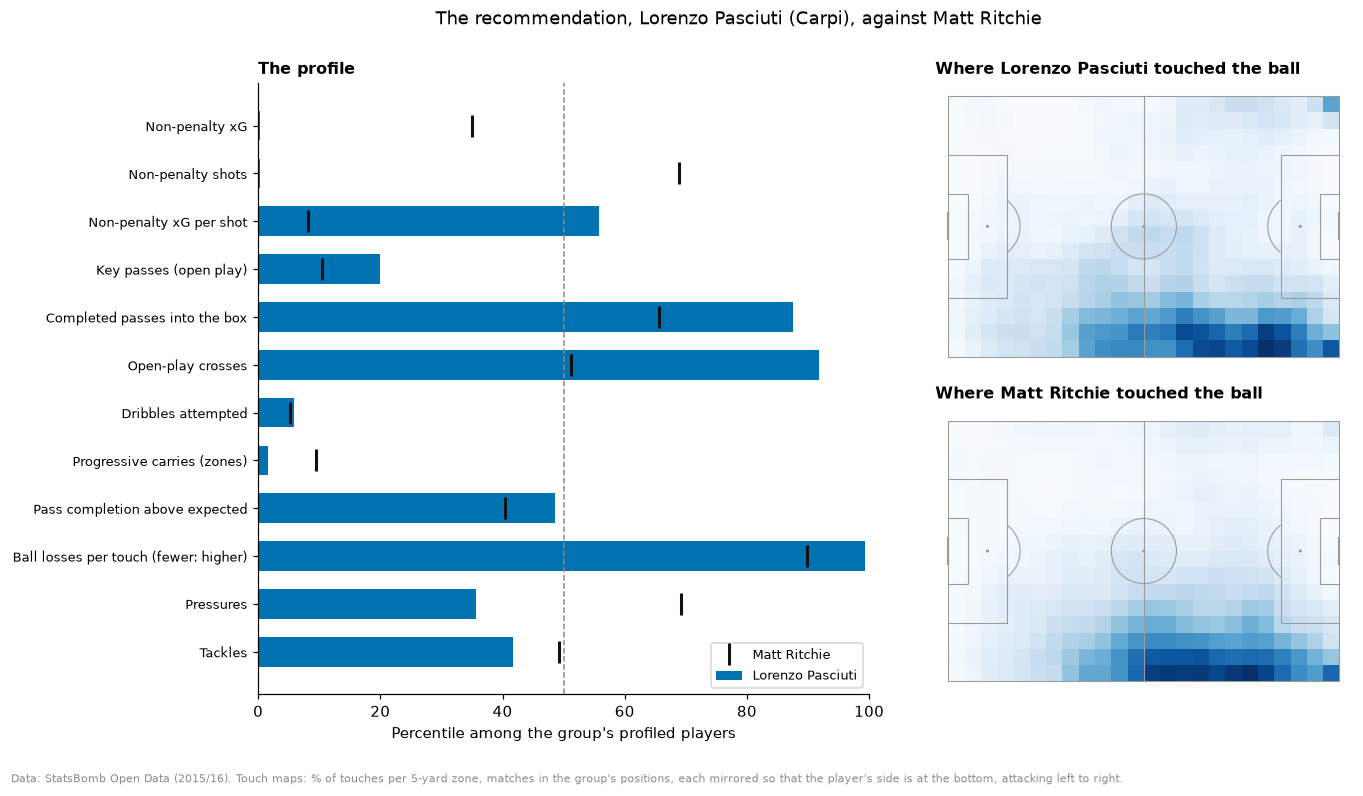

,Low end,High end,Lorenzo Pasciuti,Matt Ritchie,Lorenzo Pasciuti's end,Matt Ritchie's end
Axis,,,,,,
1,Link player,Final-third attacker,-1.03,-1.10,Link player,Link player
2,Lay-off runner,Forward passer,+1.70,+0.59,Forward passer,Forward passer
3,Inside forward,Touchline winger,+1.23,+0.91,Touchline winger,Touchline winger
4,Ball-carrier,Aerial presence,+0.95,+0.14,Aerial presence,between the two


Lorenzo Pasciuti against Matt Ritchie, in percentile points: furthest below on non-penalty shots (-69), non-penalty xG (-35), pressures (-33); furthest above on non-penalty xG per shot (+48), open-play crosses (+41), completed passes into the box (+22).


In [10]:
name = who.name[recommended]
touched = touch_map(con, rows[rows.player_id == recommended], zone=ZONE)
fig = plt.figure(figsize=(13.5, 6.8))
grid_spec = fig.add_gridspec(2, 2, width_ratios=[1, 1.05])
left = fig.add_subplot(grid_spec[:, 0])
y = np.arange(len(statistics))[::-1]
left.barh(y, percentiles.loc[recommended, statistics], height=0.62, color=OKABE_ITO[0],
          label=name)  # fmt: skip
left.plot(mine.percentile, y, "|", color="#111111", markersize=15, markeredgewidth=2,
          label=PLAYER)  # fmt: skip
left.axvline(50, color=GREY, lw=1, ls="--")
left.set_yticks(y, [LABELS[s] + (" (fewer: higher)" if s in LOWER_IS_BETTER else "")
                    for s in statistics], fontsize=8.5)  # fmt: skip
left.set_xlim(0, 100)
left.set_xlabel("Percentile among the group's profiled players")
left.grid(axis="y", visible=False)
left.legend(loc="lower right", fontsize=8.5, frameon=True)
left.set_title("The profile", fontsize=10.5)
for row, (who_id, title) in enumerate(((recommended, name), (player, PLAYER))):
    ax = fig.add_subplot(grid_spec[row, 1])
    pitch.draw(ax=ax)
    shares = (touched if who_id == recommended else touches).loc[who_id]
    grid["statistic"] = (
        gaussian_filter(shares.to_numpy().reshape(80 // ZONE, 120 // ZONE), 0.8, mode="nearest")
        * 100
    )
    pitch.heatmap(grid, ax=ax, cmap="Blues", edgecolors="none")
    ax.set_title(f"Where {title} touched the ball", fontsize=10.5)
fig.suptitle(f"The recommendation, {name} ({who.team[recommended]}), against {PLAYER}", y=1.0)
fig.tight_layout()
credit(fig, "Data: StatsBomb Open Data (2015/16). Touch maps: % of touches per 5-yard zone, "
            "matches in the group's positions, each mirrored so that the player's side is at the "
            "bottom, attacking left to right.")  # fmt: skip
plt.show()
display(
    pd.DataFrame({
        "Low end": [AXIS_NAMES[a][0] for a in scores],
        "High end": [AXIS_NAMES[a][1] for a in scores],
        name: scores.loc[recommended], PLAYER: scores.loc[player],
        f"{name}'s end": ends.loc[recommended].fillna("between the two"),
        f"{PLAYER}'s end": ends.loc[player].fillna("between the two"),
    }, index=scores.columns).rename_axis(index="Axis")
    .style.format({name: "{:+.2f}", PLAYER: "{:+.2f}"})
    .set_caption("The style axes (scores in standard deviations of the group's regulars)")
)  # fmt: skip
diff = (percentiles.loc[recommended, statistics] - mine.percentile).sort_values()
print(f"{name} against {PLAYER}, in percentile points: furthest below on "
      + ", ".join(f"{lower(LABELS[s])} ({d:+.0f})" for s, d in diff.head(3).items())
      + "; furthest above on "
      + ", ".join(f"{lower(LABELS[s])} ({d:+.0f})" for s, d in diff.tail(3)[::-1].items())
      + ".")  # fmt: skip

### 4.3 The scouting reports

In [11]:
case = recruitment.case_study(con, cfg, rows=rows, seasons=seasons)  # sections 2 and 3 again
assert case.ceiling == CEILING and case.recommended == recommended
assert case.long_list.index.equals(long_list.index)
assert case.shortlist.index.equals(shortlist.index)
assert np.allclose(case.long_list[["gap", "fit"]], long_list[["gap", "fit"]])
signed = recruitment.signings(con, case, SEASON + 1)  # read after the decision: whose page
written = write_reports(con, cfg, case, signed)
reported = list(dict.fromkeys([*shortlist.index, player, *signed]))
display(
    pd.DataFrame({
        "Player": who.name.loc[reported], "In the case study": [role(case, i) for i in reported],
        "Team": who.team.loc[reported], "Value (€M)": who.value.loc[reported] / 1e6,
        "Model over value": np.exp(case.gap.loc[reported]), "Fit to Bournemouth":
        case.fit.loc[reported], "Report": [p.name for p in written[:-1]],
    }).set_index("Player")
    .style.format({"Value (€M)": "{:.1f}", "Model over value": "{:.2f}",
                   "Fit to Bournemouth": "{:.2f}"})
    .set_caption(f"The scouting reports, in {cfg.paths.scouting.relative_to(PROJECT_ROOT)}/ with "
                 f"{written[-1].name} (Ritchie's fit: to Bournemouth's style without Ritchie)")
)  # fmt: skip
for i in signed:
    r = long_list.loc[i] if i in long_list.index else None
    where = (f"on the long list, {r['list'].lower()} {r.place} of "
             f"{(long_list['list'] == r['list']).sum()} by distance, in the "
             f"{'nearer' if r.nearer_half else 'further'} half" if r is not None
             else "not on the long list")  # fmt: skip
    print(f"The player the club signed, {who.name[i]} ({who.team[i]}, €{who.value[i] / 1e6:.1f}M "
          f"on 30 June 2016): {where}; the model's value {np.exp(case.gap[i]):.2f} times the "
          f"market's, fit {case.fit[i]:.2f}.")  # fmt: skip
print("The package's case study gives this notebook's long list, shortlist and recommendation.")

,In the case study,Team,Value (€M),Model over value,Fit to Bournemouth,Report
Player,,,,,,
Ludovic Blas,Shortlist: 1st of 5 by the gap,Guingamp,0.3,3.78,0.64,ludovic-blas.html
Adri Embarba,Shortlist: 2nd of 5 by the gap,Rayo Vallecano,1.0,2.69,0.79,adri-embarba.html
Lorenzo Pasciuti,"Shortlist: the recommendation, 3rd of 5 by the gap",Carpi,1.3,2.30,0.92,lorenzo-pasciuti.html
Jesse Lingard,Shortlist: 4th of 5 by the gap,Manchester United,5.0,1.96,0.32,jesse-lingard.html
Suso,Shortlist: 5th of 5 by the gap,Genoa,3.3,1.61,0.24,suso.html
Matt Ritchie,The player to replace,AFC Bournemouth,6.0,1.57,0.94,matt-ritchie.html
Jordon Ibe,"Long list: regulars, 29th of 34 by distance",Liverpool,7.0,1.64,0.30,jordon-ibe.html


The player the club signed, Jordon Ibe (Liverpool, €7.0M on 30 June 2016): on the long list, regulars 29 of 34 by distance, in the further half; the model's value 1.64 times the market's, fit 0.30.
The package's case study gives this notebook's long list, shortlist and recommendation.


### What section 4 shows

- **The recommendation.** Lorenzo Pasciuti (Carpi, 26, €1.3M against the model's €3.0M) fits
  Bournemouth's style best, at 0.92, ahead of Adri Embarba (0.79) and Ludovic Blas (0.64); Jesse
  Lingard (0.32) and Suso (0.24) fit it least. Pasciuti is also the nearest regular of the five to
  Ritchie (4th on the long list) and shares all three of Ritchie's axis ends: a link player, a
  forward passer and a touchline winger. Carpi finished 18th and went down.
- **Against Ritchie.** Pasciuti keeps the ball as well as Ritchie (99th percentile for ball
  losses per touch, Ritchie 90th) and crosses and passes into the box more (92nd and 88th, against
  51st and 66th), from further up the flank: the touches run to the byline, Ritchie's from the own
  half to the edge of the box. What Pasciuti lacks is Ritchie's shooting and pressing: shots and
  xG at the bottom of the group (6 non-penalty shots in 1,636 league minutes), pressures at the
  36th percentile against 69th. Fit reads the style, not the output: the recommendation fills
  Ritchie's role on the flank, not Ritchie's shots.
- **Strengths and weaknesses** by the rule: Ritchie has one strength (ball security) and three
  weaknesses (dribbles, xG per shot, progressive carries); Blas, the youngest, has no weakness,
  and Lingard's weaknesses are chance creation (key passes, dribbles and crosses at the 12th to
  18th percentile).
- **The club's choice, read the same way.** Jordon Ibe (Liverpool, 20, €7.0M) is on the long list,
  29th of its 34 regulars by distance from Ritchie, in the further half, so the rules could not
  have shortlisted Ibe; within the ceiling of €7.85M, above the €6.04M of the summer of 2016's
  ratio; the model's value 1.64 times the market's; fit 0.30. Ritchie's own fit to Bournemouth's
  style without Ritchie is 0.94: fit finds the club's own player at home.
- **The reports.** Seven pages and an index in `reports/scouting/`, from the package's steps, which
  give this notebook's long list, shortlist and recommendation exactly; each page is a single file
  of about 150 KB and rebuilds byte for byte.

## 5. What happened

The choices were made on 30 June 2016. This section reads what came after, with the back-test's
outcomes (notebook 04, section 2), for the first time in the notebook.

- **Value growth**: the market value at each horizon (31 August 2017, 2018, 2019 and 2021; three
  years on is read first) against the value on 1 August 2016, after the summer's revaluation,
  scored as a percentile among the profiled players of the same age band, players no longer valued
  at the bottom: 50 is what players of that age did on average.
- **The career**: league minutes in the season before each horizon, in the leagues Transfermarkt's
  appearances cover, and the club named on the latest valuation. A club outside those leagues has
  no minutes on record, which is not the end of a career.
- **The players**: the shortlist, Ritchie and Ibe side by side at each horizon, and Ibe's share of
  Bournemouth's league minutes season by season.
- **Against chance**: the shortlist's mean score against every pick of five from the nearer half
  of the long list, the pool it was drawn from, each pick equally likely; the recommendation's and
  Ibe's places among the 42 players of the long list.
- **What it can show**: one club, one summer and five players make a case, not a test. And the
  outcomes are what happened where the players went, not what they would have done at
  Bournemouth; only Ibe's are Bournemouth's.

### 5.1 The players, three and five years on

,In the case study,Age,"Value, 1 Aug 2016 (€M)","Value, 31 Aug 2019 (€M)","Club, 31 Aug 2019","League minutes, 2018/19","League, 2018/19","Score, 2017","Score, 2018","Score, 2019","Score, 2021"
Player,,,,,,,,,,,
Lorenzo Pasciuti,Recommended,26,1.4,0.6,Carpi FC 1909,0,–,17,17,20,21
Adri Embarba,Shortlisted,24,1.5,4.0,Rayo Vallecano,"2,291",La Liga,42,62,79,96
Ludovic Blas,Shortlisted,18,0.8,5.0,EA Guingamp,"2,376",Ligue 1,93,87,79,95
Jesse Lingard,Shortlisted,23,6.0,40.0,Manchester United,"1,670",Premier League,92,98,96,92
Suso,Shortlisted,22,5.5,40.0,AC Milan,"3,031",Serie A,93,92,91,79
Matt Ritchie,Sold,26,6.0,12.0,Newcastle United,"2,940",Premier League,83,85,82,55
Jordon Ibe,Signed,20,10.0,8.0,AFC Bournemouth,795,Premier League,16,16,19,4


/tmp/ipykernel_3688374/3648965384.py:62: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  left.text(HORIZONS[-1] + pd.Timedelta(days=25), 10**y, who.name[i], va="center", fontsize=8,
/tmp/ipykernel_3688374/3648965384.py:65: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  left.text(MARKET_VIEW + pd.Timedelta(days=20), 0.97, "30 June 2016: the decision", fontsize=7.5,
/tmp/ipykernel_3688374/3648965384.py:75: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  left.set_xlim(MARKET_VIEW - pd.Timedelt

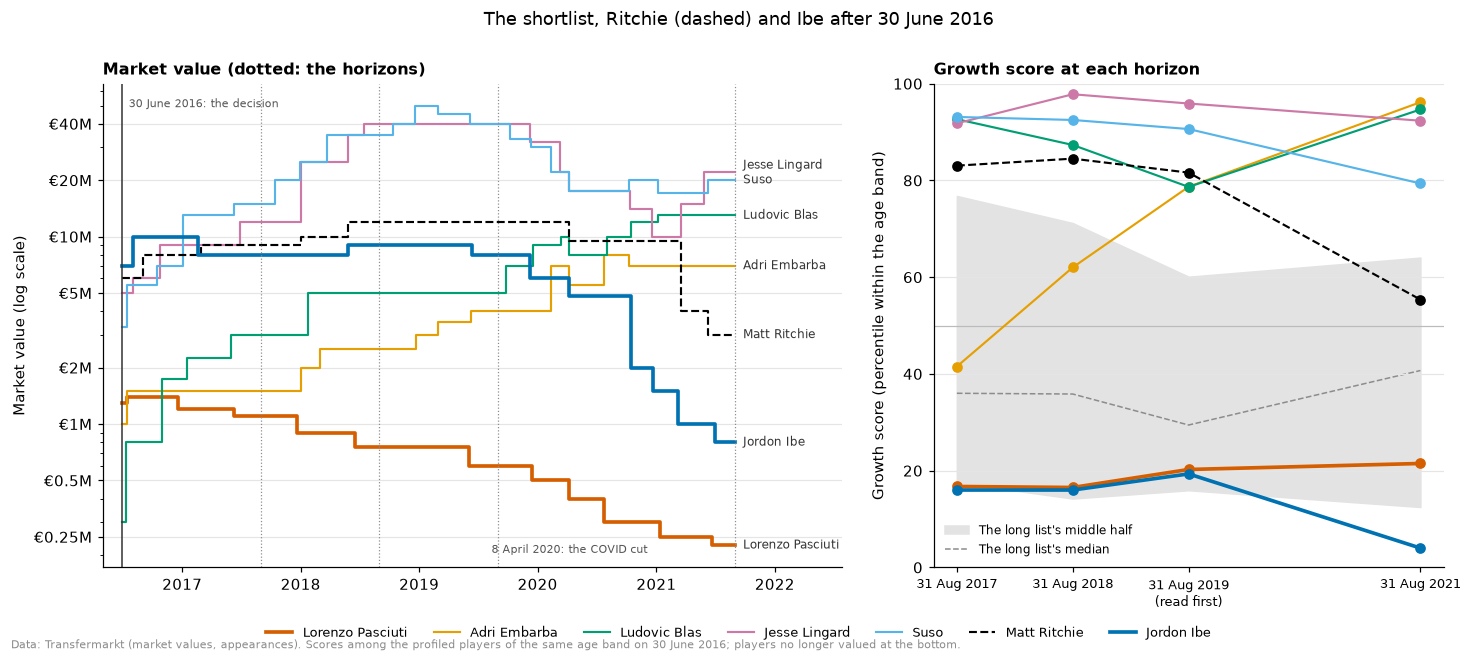

Lorenzo Pasciuti: the clubs named at the horizons, Carpi FC 1909 (2017, 2018, 2019), Carrarese Calcio 1908 (2021).
Jordon Ibe: the clubs named at the horizons, AFC Bournemouth (2017, 2018, 2019), Derby County (2021).
Jordon Ibe's share of AFC Bournemouth's league minutes: 31% in 2016/17, 59% in 2017/18, 23% in 2018/19.


In [12]:
outcomes = player_outcomes(con, cfg)  # read after the market view, as in notebook 04
HORIZONS = [pd.Timestamp(h) for h in cfg.backtest.horizons]
PRIMARY = pd.Timestamp(cfg.backtest.primary_horizon)  # three years on, read first
seven = list(dict.fromkeys([*side.index, player, *signed]))  # the shortlist by fit
after = outcomes[outcomes.player_id.isin(seven)].set_index(["player_id", "horizon"])
at = after.xs(PRIMARY, level="horizon").loc[seven]
score = after.score.unstack("horizon").loc[seven]
in_case = pd.Series({i: "Shortlisted" for i in side.index} | {recommended: "Recommended",
                     player: "Sold"} | dict.fromkeys(signed, "Signed"))  # fmt: skip
season_name = f"{PRIMARY.year - 1}/{PRIMARY.year % 100:02d}"
display(
    pd.DataFrame({
        "Player": who.name.loc[seven], "In the case study": in_case.loc[seven],
        "Age": who.age.loc[seven].astype(int),
        "Value, 1 Aug 2016 (€M)": at.base / 1e6, f"Value, {PRIMARY:%-d %b %Y} (€M)": at.value / 1e6,
        f"Club, {PRIMARY:%-d %b %Y}": at.club,
        f"League minutes, {season_name}": at.league_minutes,
        f"League, {season_name}": at.league.map(lambda c: league_name.get(c, c)).fillna("–"),
        **{f"Score, {h.year}": score[h] for h in HORIZONS},
    }).set_index("Player")
    .style.format({"Value, 1 Aug 2016 (€M)": "{:.1f}", f"Value, {PRIMARY:%-d %b %Y} (€M)": "{:.1f}",
                   f"League minutes, {season_name}": "{:,.0f}"}
                  | {f"Score, {h.year}": "{:.0f}" for h in HORIZONS})
    .set_caption("The shortlist (by fit), Ritchie and the player the club signed: value, club and "
                 "league minutes three years on (minutes in the covered leagues, in the season "
                 "before the horizon), and the growth score at each horizon (a percentile within "
                 "the age band, 50 the average)")
)  # fmt: skip

valuations = pool_valuations(con)
valuations = valuations[valuations.player_id.isin(seven)]
start = value_at(valuations, MARKET_VIEW).value  # what the club saw
COVID_CUT = pd.Timestamp("2020-04-08")  # the flat cut of almost every value
colors = dict(zip(seven, [OKABE_ITO[5], OKABE_ITO[1], OKABE_ITO[2], OKABE_ITO[3], OKABE_ITO[4],
                          "#000000", OKABE_ITO[0]], strict=True))  # fmt: skip
long_scores = outcomes[outcomes.player_id.isin(long_list.index)].pivot(
    index="player_id", columns="horizon", values="score"
)
assert long_scores.index.sort_values().equals(long_list.index.sort_values())
assert long_scores.notna().all().all()

years = [h.year for h in HORIZONS]
fig, (left, right) = plt.subplots(1, 2, figsize=(13.5, 5.6),
                                  gridspec_kw={"width_ratios": [1.45, 1]})  # fmt: skip
ends_at = {}
for i in seven:
    v = valuations[
        (valuations.player_id == i)
        & valuations.date.between(MARKET_VIEW, HORIZONS[-1], inclusive="right")
    ]
    dates = [MARKET_VIEW, *v.date, HORIZONS[-1]]
    path = [start[i], *v.value, (v.value.iloc[-1] if len(v) else start[i])]
    style = {"lw": 2.4 if i in (recommended, *signed) else 1.4,
             "ls": "--" if i == player else "-", "color": colors[i]}  # fmt: skip
    left.plot(dates, np.array(path) / 1e6, drawstyle="steps-post", **style, label=who.name[i])
    right.plot(years, score.loc[i], marker="o", markersize=6, **style)
    ends_at[i] = np.log10(path[-1] / 1e6)
placed, last = {}, -np.inf
for i, y in sorted(ends_at.items(), key=lambda kv: kv[1]):  # labels at least 0.08 decades apart
    placed[i] = last = max(y, last + 0.08)
for i, y in placed.items():
    left.text(HORIZONS[-1] + pd.Timedelta(days=25), 10**y, who.name[i], va="center", fontsize=8,
              color="#333333")  # fmt: skip
left.axvline(MARKET_VIEW, color="#333333", lw=1)
left.text(MARKET_VIEW + pd.Timedelta(days=20), 0.97, "30 June 2016: the decision", fontsize=7.5,
          color="#555555", transform=left.get_xaxis_transform(), va="top")  # fmt: skip
for h in HORIZONS:
    left.axvline(h, color=GREY, lw=0.8, ls=":")
left.annotate("8 April 2020: the COVID cut", (COVID_CUT, 0.03), xycoords=("data", "axes fraction"),
              fontsize=7.5, color="#555555", ha="center")  # fmt: skip
left.set_yscale("log")
ticks = [0.25, 0.5, 1, 2, 5, 10, 20, 40]
left.set_yticks(ticks, [f"€{t:g}M" for t in ticks])
left.yaxis.set_minor_formatter(NullFormatter())
left.set_xlim(MARKET_VIEW - pd.Timedelta(days=60), HORIZONS[-1] + pd.Timedelta(days=330))
left.xaxis.set_major_locator(mdates.YearLocator())
left.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
left.set_ylabel("Market value (log scale)")
left.set_title("Market value (dotted: the horizons)", fontsize=10.5)
quartiles = long_scores[HORIZONS].quantile([0.25, 0.5, 0.75])
right.fill_between(years, quartiles.loc[0.25], quartiles.loc[0.75], color="#E3E3E3",
                   label="The long list's middle half", zorder=0)  # fmt: skip
right.plot(years, quartiles.loc[0.5], color=GREY, lw=1, ls="--",
           label="The long list's median", zorder=1)  # fmt: skip
right.axhline(50, color="#BBBBBB", lw=0.8, zorder=0)
right.set_xticks(years, [f"{h:%-d %b %Y}" + ("\n(read first)" if h == PRIMARY else "")
                         for h in HORIZONS], fontsize=8.5)  # fmt: skip
right.set_ylim(0, 100)
right.set_ylabel("Growth score (percentile within the age band)")
right.set_title("Growth score at each horizon", fontsize=10.5)
right.legend(loc="lower left", fontsize=8)
right.grid(axis="x", visible=False)
fig.legend(*left.get_legend_handles_labels(), loc="lower center", ncol=len(seven), fontsize=8.5,
           bbox_to_anchor=(0.5, -0.04), frameon=False)  # fmt: skip
fig.suptitle("The shortlist, Ritchie (dashed) and Ibe after 30 June 2016", y=1.0)
fig.tight_layout()
credit(fig, "Data: Transfermarkt (market values, appearances). Scores among the profiled players "
            "of the same age band on 30 June 2016; players no longer valued at the "
            "bottom.")  # fmt: skip
plt.show()


def clubs_named(i):
    """The clubs named on the player's valuations at the horizons, in turn."""
    named = after.club.loc[i]
    runs = named.groupby((named != named.shift()).cumsum())
    return ", ".join(f"{d.iloc[0]} ({', '.join(str(h.year) for h in d.index)})" for _, d in runs)


for i in (recommended, *signed):
    print(f"{who.name[i]}: the clubs named at the horizons, {clubs_named(i)}.")
for i in signed:
    pair = pd.DataFrame({"player_id": [i], "club_id": [club_of[club]]})
    shares = {s: league_share(con, s, pair)[0] for s in range(SEASON + 1, PRIMARY.year)}
    print(f"{who.name[i]}'s share of {CLUB}'s league minutes: " + ", ".join(
        f"{share:.0%} in {s}/{(s + 1) % 100:02d}" for s, share in shares.items()
    ) + ".")  # fmt: skip

### 5.2 Against chance

In [13]:
pool = long_list.index[long_list.nearer_half]  # what the shortlist was drawn from
named = {i: f"{who.name[i]}'s place" for i in (recommended, *signed)}
group_mean = outcomes[outcomes.comparison_group == GROUP].groupby("horizon").score.mean()
against = {}
for h in HORIZONS:
    s = long_scores[h]
    picks = chance(s.loc[pool], SHORT)  # every pick of five, each equally likely
    mean = s.loc[shortlist.index].mean()
    place_of = s.rank(ascending=False, method="min")
    against[f"{h:%-d %b %Y}"] = {
        "The shortlist's mean": mean,
        "Picks of five: median": np.median(picks),
        "Picks of five: 95th percentile": np.percentile(picks, 95),
        "Picks at or above the shortlist": (picks >= mean - 1e-9).mean(),
        **{c: place_of.get(i, np.nan) for i, c in named.items()},
        "Nearer half's mean": s.loc[pool].mean(),
        "Further half's mean": s.drop(pool).mean(),
        f"The group's {len(players[group == GROUP])} profiled players' mean": group_mean[h],
    }
against = pd.DataFrame(against).T
display(
    against.style.format("{:.1f}").format("{:.1%}", subset="Picks at or above the shortlist")
    .format("{:.0f}", subset=list(named.values()))
    .set_caption(f"The shortlist against every pick of {SHORT} from the nearer half of the long "
                 f"list ({len(picks):,} picks of the {len(pool)} players), and places among the "
                 f"{len(long_list)} of the long list by growth score (1: the highest)")
)  # fmt: skip
first = against.loc[f"{PRIMARY:%-d %b %Y}"]
print(f"Three years on the shortlist's mean score was {first.iloc[0]:.1f}, against a median "
      f"{first.iloc[1]:.1f} for a pick of {SHORT} from the nearer half: "
      f"{first['Picks at or above the shortlist']:.1%} of the {len(picks):,} picks did as well. "
      f"Places among the {len(long_list)} of the long list: "
      + ", ".join(f"{who.name[i]} {first[c]:.0f}" for i, c in named.items()) + ".")  # fmt: skip

,The shortlist's mean,Picks of five: median,Picks of five: 95th percentile,Picks at or above the shortlist,Lorenzo Pasciuti's place,Jordon Ibe's place,Nearer half's mean,Further half's mean,The group's 305 profiled players' mean
31 Aug 2017,67.2,38.9,60.1,1.7%,33,35,38.9,53.5,49.3
31 Aug 2018,71.2,40.5,60.8,0.5%,30,31,40.8,45.5,49.8
31 Aug 2019,72.8,37.3,58.2,0.2%,26,29,37.6,41.3,52.0
31 Aug 2021,76.8,40.5,62.3,0.2%,29,39,40.7,44.1,51.0


Three years on the shortlist's mean score was 72.8, against a median 37.3 for a pick of 5 from the nearer half: 0.2% of the 20,349 picks did as well. Places among the 42 of the long list: Lorenzo Pasciuti 26, Jordon Ibe 29.


### What section 5 shows

- **The shortlist did well; the recommendation did not.** Three years on, four of the five
  shortlisted players stood at the 79th percentile of their age band or above: Jesse Lingard (96th;
  Manchester United, €40M), Suso (91st; AC Milan, €40M), Adri Embarba (79th; Rayo Vallecano, back
  in La Liga, €4M) and Ludovic Blas (79th; Guingamp, €5M), all regulars in the big five. Lorenzo
  Pasciuti, the recommendation, stayed at Carpi, outside the leagues on record, and was valued at
  €0.6M in 2019 against €1.4M on 1 August 2016 (20th percentile); Carrarese by 2021, at €0.2M.
- **Against chance.** The shortlist's mean score three years on, 72.8, against a median 37.3 for
  a pick of five from the nearer half of the long list: 0.2% of the 20,349 picks did as well, and
  at most 1.7% at any horizon. The long list itself grew less than the group: a mean 37.6 in the
  nearer half and 41.3 in the further half, against 52.0 for the group's 305 profiled players.
  Most players the budget allowed were valued low for a reason; the gap found the exceptions, as
  its picks did in the back-test (63rd percentile three years on, notebook 04; 73rd here).
- **Fit ran the other way.** Ordered by fit, the shortlist came out almost in reverse: Pasciuti
  (fit 0.92) last, Lingard (0.32) and Suso (0.24), the two who fitted Bournemouth least, first and
  second. Value growth is not what fit was chosen for: fit went with minutes at the club (notebook
  07, section 4), and none of the five went to Bournemouth, so how Pasciuti would have played there
  cannot be seen. What can be seen is that the step chosen to decide among the five picked the
  one whose career went worst.
- **The club's choice.** Jordon Ibe played 31%, 59% and 23% of Bournemouth's league minutes in
  the three seasons after the signing, was valued at €8M in 2019 against €10M on 1 August 2016
  (19th percentile of the age band) and at €0.8M at Derby County by 2021 (4th). Among the 42 of
  the long list three years on, Pasciuti was 26th and Ibe 29th: the rules' pick and the club's
  did about as badly. Ritchie, sold for twice the market value, was at the 82nd percentile three
  years on (€12M at Newcastle United, 2,940 league minutes in 2018/19).
- **What one case can show.** One club, one summer and five players: the shortlist's place
  against chance is the gap's result again on a new set of players, not proof of it, and the
  recommendation's miss is one player. The rules stay as they were set; changing the last step
  after seeing the outcome would be choosing by hindsight.